# 02 · From Mathematics to Stored Values

**NHyDB 0.28.2 notebook series · v1**

Notebook 01 showed that every cell *is* a number. Now we put real data into these cells: create a database, write records, see **where** they live in the Dynadron, read the same value on three different ways, close the database and open it again.

> **Who is this for?** This notebook starts with a short introduction and continues with runnable examples. **New to NHyDB?** Read from top to bottom – every idea is introduced before it is used. **Already know the basics?** Skip the sections marked 📘 *Background* and jump to the experiments marked ▶. All cells run from top to bottom; optional deep dives are marked ⏩ *Advanced*.

**What you will learn**

* how to create a database with a realm, a shape and a CLASSIC layout
* where each stored value lives: its cell `(R, u, v, lane)` and its number `N`
* three ways to the same value: by coordinates, by record and by `N`
* why a huge address space does **not** mean a huge file

**Recommended before:** [01 · The Address Is the Identity](01_the_address_is_the_identity_v1.ipynb).

### Setup

The next cell checks the environment and defines a few small plotting helpers used in
this notebook. It is collapsed because it is not about NHyDB itself – feel free to open
it. Every database in this notebook lives in a temporary folder that is removed at
the end.

In [1]:
import math
import os
import shutil
import sys
import tempfile

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle

import nhydb

# --- environment check ---------------------------------------------------------
EXPECTED = "0.28.2"
print(f"Python {sys.version.split()[0]} · nhydb {nhydb.ENGINE_VERSION} · "
      f"file format {nhydb.FILE_FORMAT_VERSION} · matplotlib {matplotlib.__version__}")
if nhydb.ENGINE_VERSION != EXPECTED:
    print(f"⚠ This notebook was written for NHyDB {EXPECTED}; results may differ.")

# --- a private temporary folder for all databases of this notebook --------------
WORKDIR = tempfile.mkdtemp(prefix="nhydb_notebook_")


def db_path(name):
    """Path of a new database file inside the temporary folder."""
    return os.path.join(WORKDIR, name)


def cleanup():
    shutil.rmtree(WORKDIR, ignore_errors=True)


def file_sizes(path):
    """Sizes of the files that belong to a database (bytes)."""
    folder, base = os.path.split(path)
    return {f: os.path.getsize(os.path.join(folder, f))
            for f in sorted(os.listdir(folder)) if f.startswith(base)}


# --- one visual language for the whole series -----------------------------------
# Layer A (mathematical address space) = blue tones, layer B (logical data model) =
# green, layer C (storage engine) = slate grey. Lanes and boundary points belong to A.
COLORS = {
    "A": "#1d4ed8", "A_light": "#dbeafe",
    "B": "#15803d", "B_light": "#dcfce7",
    "C": "#475569", "C_light": "#e2e8f0",
    "NL": "#2563eb", "NR": "#7c3aed",
    "GZ": "#dc2626", "N0": "#9ca3af",
    "attention": "#ea580c", "ok": "#16a34a", "bad": "#dc2626",
}
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 100, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 11,
})


def kind_of(n):
    """'NL', 'NR', 'GZ' or 'N0' for a natural number n >= 1 (computed by NHyDB)."""
    try:
        return nhydb.n_to_dynadron_address(n)["lane_name"]
    except nhydb.AddressError:
        return "GZ" if math.isqrt(n) ** 2 == n else "N0"


def group_of(n):
    """The group G whose interval [G(G-1), G(G+1)) contains n."""
    g = math.isqrt(n)
    return g + 1 if n - g * g >= g else g       # N0(g+1) and the NL cells of g+1 lie above g² + g − 1


KIND_LABEL = {"NL": "NL cell", "NR": "NR cell", "GZ": "GZ point (G²)", "N0": "N0 point (G·(G−1))"}


def plot_staircase(ax, g_max=10, highlight=(), annotate=True, title=None, g_min=1):
    """Every natural number 1 … g_max·(g_max+1)−1 in its group row.

    Row G holds the numbers G(G−1) … G(G+1)−1. The horizontal position is N − G²:
    NL cells sit at −u (left of the square G²), NR cells at +v (right of it).
    """
    highlight = set(highlight)
    for g in range(g_min, g_max + 1):
        for n in range(max(1, g * (g - 1)), g * (g + 1)):
            k = kind_of(n)
            x, y = n - g * g, -g
            face = COLORS[k]
            alpha = 1.0 if k in ("GZ", "N0") else 0.85
            ax.add_patch(Rectangle((x - 0.47, y - 0.42), 0.94, 0.84, facecolor=face, alpha=alpha,
                                   edgecolor=COLORS["attention"] if n in highlight else "white",
                                   linewidth=2.6 if n in highlight else 0.5))
            if annotate:
                ax.text(x, y, str(n), ha="center", va="center", color="white",
                        fontsize=7 if n < 100 else 6, fontweight="bold")
    ax.set_xlim(-g_max - 1, g_max)
    ax.set_ylim(-g_max - 0.8, -g_min + 0.8)
    ax.set_yticks([-g for g in range(g_min, g_max + 1)])
    ax.set_yticklabels([f"G={g}" for g in range(g_min, g_max + 1)])
    ax.set_xlabel("position in the group:  N − G²   (NL: −u   ·   GZ: 0   ·   NR: +v)")
    ax.axvline(0, color=COLORS["GZ"], lw=0.8, ls=":", zorder=0)
    ax.xaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))
    ax.spines["left"].set_visible(False)
    handles = [Rectangle((0, 0), 1, 1, color=COLORS[k]) for k in ("N0", "NL", "GZ", "NR")]
    ax.legend(handles, [KIND_LABEL[k] for k in ("N0", "NL", "GZ", "NR")], ncol=4,
              loc="upper center", bbox_to_anchor=(0.5, -0.12), frameon=False, fontsize=9)
    if title:
        ax.set_title(title)


def plot_address_grid(ax, u_max, v_max, lane, highlight=(), annotate=True, title=None, values=None):
    """The (u, v) plane of realm 1 for one lane; every square shows its number N.

    Anti-diagonals u + v = G are the groups. ``highlight`` is a set of (u, v);
    ``values`` maps (u, v) to a short text shown under N (stored data).
    """
    import matplotlib.colors as mcolors
    base = COLORS[lane]
    cmap = mcolors.LinearSegmentedColormap.from_list(lane, ["#ffffff", base])
    highlight = set(highlight)
    g_top = u_max + v_max
    for u in range(1, u_max + 1):
        for v in range(1, v_max + 1):
            n = nhydb.dynadron_n(1, u, v, lane)
            g = u + v
            shade = 0.25 + 0.6 * (g - 2) / max(1, g_top - 2)
            ax.add_patch(Rectangle((u - 0.5, v - 0.5), 1, 1, facecolor=cmap(shade),
                                   edgecolor=COLORS["attention"] if (u, v) in highlight else "white",
                                   linewidth=2.6 if (u, v) in highlight else 0.8, zorder=2 if (u, v) in highlight else 1))
            if annotate:
                txt = str(n)
                if values and (u, v) in values:
                    txt += "\n" + str(values[(u, v)])
                ax.text(u, v, txt, ha="center", va="center", fontsize=7.5 if n < 1000 else 6.5,
                        color="white" if shade > 0.55 else "#111827", zorder=3)
    for g in range(2, g_top + 1):        # group diagonals u + v = G
        ax.plot([g - v_max - 0.5, g - 0.5], [v_max + 0.5, 0.5], color="#94a3b8", lw=0.4, zorder=0)
    ax.set_xlim(0.5, u_max + 0.5)
    ax.set_ylim(0.5, v_max + 0.5)
    ax.set_xticks(range(1, u_max + 1))
    ax.set_yticks(range(1, v_max + 1))
    ax.set_xlabel("u")
    ax.set_ylabel("v")
    ax.set_aspect("equal")
    ax.set_title(title or f"lane {lane}:  N = G² {'−' if lane == 'NL' else '+'} {'u' if lane == 'NL' else 'v'}",
                 color=base)


def plot_path(ax, steps, title=None):
    """'From input to value': boxes coloured by layer A/B/C, connected by arrows.

    ``steps`` is a list of (layer, heading, text) with layer in {"A", "B", "C"}.
    """
    n = len(steps)
    width, gap = 1.0, 0.35
    for i, (layer, head, text) in enumerate(steps):
        x = i * (width + gap)
        ax.add_patch(FancyBboxPatch((x, 0), width, 1, boxstyle="round,pad=0.02,rounding_size=0.06",
                                    facecolor=COLORS[layer + "_light"], edgecolor=COLORS[layer], lw=1.6))
        ax.text(x + width / 2, 0.80, head, ha="center", va="center", fontsize=8.5,
                fontweight="bold", color=COLORS[layer])
        ax.text(x + width / 2, 0.40, text, ha="center", va="center", fontsize=8, color="#111827",
                wrap=True)
        if i < n - 1:
            ax.annotate("", xy=(x + width + gap - 0.02, 0.5), xytext=(x + width + 0.02, 0.5),
                        arrowprops=dict(arrowstyle="-|>", color="#334155", lw=1.3))
    ax.set_xlim(-0.1, n * (width + gap) - gap + 0.1)
    ax.set_ylim(-0.35, 1.15)
    ax.axis("off")
    for j, (layer, name) in enumerate([("A", "A · address space"), ("B", "B · data model"),
                                       ("C", "C · storage engine")]):
        ax.text(j * 1.6, -0.25, "■ " + name, color=COLORS[layer], fontsize=8.5, fontweight="bold")
    if title:
        ax.set_title(title)

import pandas as pd

Python 3.14.5 · nhydb 0.28.2 · file format 0.28.2 · matplotlib 3.11.2


## 📘 Background: three small building blocks

| Term | Meaning | Here |
|---|---|---|
| **Realm** | a numbered address range | realm `1`, called *library* |
| **Shape** | the typed fields of a record (`v = 1 … k`) | *book*: `title`, `author`, `year` |
| **Layout** | how records are placed on cells | **CLASSIC**: record = `u`, field = `v` |

In a CLASSIC layout, record number 2 is the row `u = 2`, and its fields are the cells
`v = 1, 2, 3` of that row. Nothing else is needed – no table, no key column.

## 1 · Create a database and write data

**Question:** What does it take to store a few records?

▶ **Run it:** we create the database, define realm, shape and layout, and write in three
different ways – one record, a batch of records, and a single extra cell on the other lane
(a note on the NR lane of book 2). Leaving the `with` block commits and closes.

In [2]:
PATH = db_path("library.nhydb")

with nhydb.create(PATH) as db:
    db.create_realm(1, "library")
    db.create_shape(1, 1, "book", [
        {"v": 1, "name": "title",  "type": "utf8"},
        {"v": 2, "name": "author", "type": "utf8"},
        {"v": 3, "name": "year",   "type": "u16"},
    ])
    db.create_classic_layout(1, 1, "books", shape_id=1)       # layout 1 in realm 1

    db.put_record(1, 1, {"title": "Flatland", "author": "Abbott", "year": 1884})   # one record
    db.put_dense_batch(1, 2, [                                                       # u = 2, 3, 4
        ["Gödel, Escher, Bach", "Hofstadter", 1979],
        ["The Joy of x", "Strogatz", 2012],
        ["Proofs from THE BOOK", "Aigner & Ziegler", 1998],
    ], shape_id=1)
    db.put_cell(1, 2, 1, "signed copy", type="utf8", lane="NR")                     # one cell

print("files:", file_sizes(PATH))

files: {'library.nhydb': 9408, 'library.nhydb.layout.enc': 1462, 'library.nhydb.layout.key': 160, 'library.nhydb.lock': 0}


**What happened?** Four files appeared. `library.nhydb` holds the data, `.layout.enc` the
encrypted schema (realm, shape, layout), `.layout.key` its key and `.lock` the writer lock.
Notebooks 11 and 12 look at them in detail.

## 2 · Where does the data live?

**Question:** Which cells did we just fill – and which numbers are they?

▶ **Run it:** NHyDB can list every materialized cell together with its address and its `N`.

In [3]:
with nhydb.open(PATH) as db:
    cells = list(db.iter_materialized_cells(1, lane="NL")) + list(db.iter_materialized_cells(1, lane="NR"))

table = pd.DataFrame([{"N": int(c["N"][1:]), "u (record)": c["u"], "v": c["v"], "lane": c["lane_name"],
                       "field": c.get("field") or "–", "value": c["value"]} for c in cells])
table.sort_values(["lane", "u (record)", "v"]).set_index("N")

,u (record),v,lane,field,value
N,,,,,
3,1,1,NL,title,Flatland
8,1,2,NL,author,Abbott
15,1,3,NL,year,1884
7,2,1,NL,title,"Gödel, Escher, Bach"
14,2,2,NL,author,Hofstadter
23,2,3,NL,year,1979
13,3,1,NL,title,The Joy of x
22,3,2,NL,author,Strogatz
33,3,3,NL,year,2012


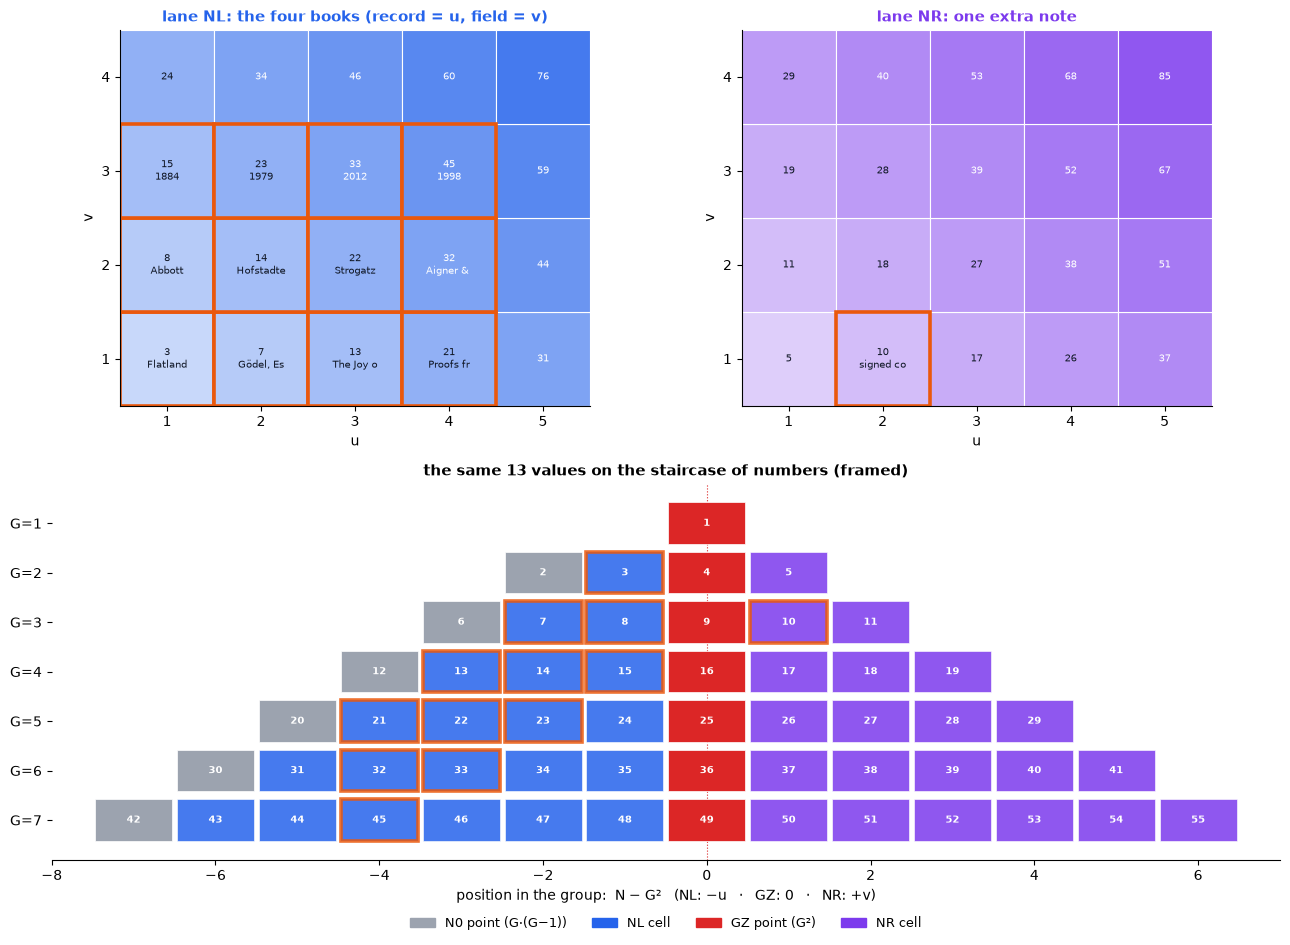

In [4]:
values_nl = {(c["u"], c["v"]): str(c["value"])[:9] for c in cells if c["lane_name"] == "NL"}
values_nr = {(c["u"], c["v"]): str(c["value"])[:9] for c in cells if c["lane_name"] == "NR"}

fig = plt.figure(figsize=(13, 9.5))
ax1 = fig.add_subplot(2, 2, 1)
ax2 = fig.add_subplot(2, 2, 2)
ax3 = fig.add_subplot(2, 1, 2)
plot_address_grid(ax1, 5, 4, "NL", highlight=values_nl, values=values_nl,
                  title="lane NL: the four books (record = u, field = v)")
plot_address_grid(ax2, 5, 4, "NR", highlight=values_nr, values=values_nr,
                  title="lane NR: one extra note")
stored = {int(c["N"][1:]) for c in cells}
plot_staircase(ax3, g_max=7, highlight=stored,
               title="the same 13 values on the staircase of numbers (framed)")
plt.tight_layout()
plt.show()

**What happened? – a record is a row of cells, not a row of neighbours**

* In the address plane (top) a book is a simple **column** `u` with its fields at `v = 1, 2, 3`.
* On the staircase (bottom) the same cells are **spread over different groups**: the title of
  book 1 is `N = 3` (group 2), its author `N = 8` (group 3), its year `N = 15` (group 4).
* That does not matter at all: each number is *computed* from `(u, v)` in a few
  arithmetic steps. Neighbourhood on the number line is not needed to find anything.
* The note on the NR lane shares `(u, v) = (2, 1)` with the title of book 2 – it is still a
  different cell with a different number (`N = 10` instead of `N = 7`).

## 3 · Three ways to the same value

**Question:** How can we read a value back?

There are three equivalent ways – choose whatever your application knows:

1. **By coordinates** (layer A): realm, `u`, `v`, lane.
2. **By record** (layer B): layout and object number, then the field name.
3. **By number** (layer A): just `N`.

▶ **Run it:** the author of book 3, read three times.

In [5]:
U, V = 3, 2                                  # book 3, field 2 = author
N = nhydb.dynadron_n(1, U, V, "NL")

with nhydb.open(PATH) as db:
    by_coordinates = db.get_value(1, U, V)               # realm, u, v (lane NL is the default)
    by_record = db.get_record(1, U)["author"]            # layout 1, object 3
    by_number = db.get_n(N, mode="cell")                 # only the number

print(f"by coordinates (1, {U}, {V}, NL): {by_coordinates!r}")
print(f"by record      layout 1, object {U}: {by_record!r}")
print(f"by number      N = {N}: {by_number['value']!r}   (field {by_number['field']!r}, record_N {by_number['record_N']})")
assert by_coordinates == by_record == by_number["value"] == "Strogatz"

by coordinates (1, 3, 2, NL): 'Strogatz'
by record      layout 1, object 3: 'Strogatz'
by number      N = 22: 'Strogatz'   (field 'author', record_N N13)


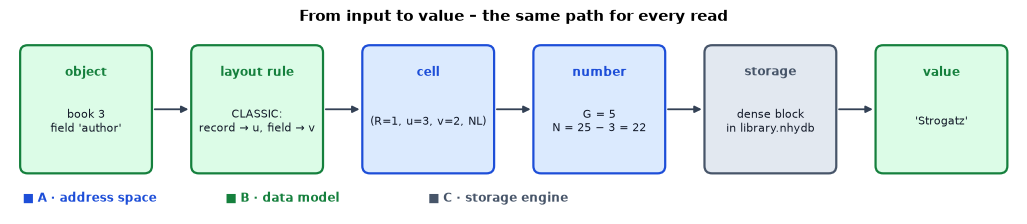

In [6]:
fig, ax = plt.subplots(figsize=(13, 2.4))
plot_path(ax, [
    ("B", "object", "book 3\nfield 'author'"),
    ("B", "layout rule", "CLASSIC:\nrecord → u, field → v"),
    ("A", "cell", f"(R=1, u={U}, v={V}, NL)"),
    ("A", "number", f"G = {U + V}\nN = {(U+V)**2} − {U} = {N}"),
    ("C", "storage", "dense block\nin library.nhydb"),
    ("B", "value", "'Strogatz'"),
], title="From input to value – the same path for every read")
plt.show()

**What happened?** All three ways end at the same cell. The colours show the three layers of
the series: **green** is your data model (books, fields), **blue** is the mathematical address
space, **grey** is the storage engine that keeps the bytes on disk.

### Reading a whole record by its number

The first field of a record (`v = 1`) is its **anchor**. Its number is the record's own number,
`record_N`. Reading an anchor number returns the whole record:

In [7]:
anchor_n = nhydb.dynadron_n(1, 3, 1, "NL")
with nhydb.open(PATH) as db:
    rec = db.get_n(anchor_n)                          # mode "auto": anchor → record
    info = db.describe_n(N)                           # what is N = 22?

print(f"N{anchor_n} → {rec['effective_mode']}: {rec['data']}")
print(f"cells of this record: {[c['N'] for c in rec['cells']]}")
print(f"N{N} is {info['interpretation']['kind']} of record {info['interpretation']['record']}, "
      f"field {info['interpretation']['field']!r} in layout {info['layout']['name']!r}")
assert rec["data"]["title"] == "The Joy of x"

N13 → record: {'title': 'The Joy of x', 'author': 'Strogatz', 'year': 2012}
cells of this record: ['N13', 'N22', 'N33']
N22 is record_cell of record 3, field 'author' in layout 'books'


## 4 · Close, reopen, everything is there

**Question:** Is the data really persistent?

The `with` blocks above already closed and reopened the database several times. Here is the
explicit check: compare everything before and after a fresh open.

In [8]:
with nhydb.open(PATH) as db:
    before = [db.get_record(1, u) for u in range(1, 5)]
    note = db.get_value(1, 2, 1, lane="NR")

# ... the database is closed here; a new process could open it now ...

with nhydb.open(PATH) as db:
    after = [db.get_record(1, u) for u in range(1, 5)]
    assert after == before and db.get_value(1, 2, 1, lane="NR") == note
    print(f"{len(after)} records and the note survived closing and reopening. ✓")
    print(f"recovered_tail_bytes = {db.recovered_tail_bytes} (nothing uncommitted was lost)")

4 records and the note survived closing and reopening. ✓
recovered_tail_bytes = 0 (nothing uncommitted was lost)


## 5 · A huge address space is not a huge file

**Question:** Realm 1 alone has `v` positions up to `10^100`. Does writing far away cost space?

▶ **Run it:** we write one small value at increasingly distant addresses and measure the file
after each commit. The addresses grow by a factor of a billion each time.

In [9]:
FAR = db_path("far_away.nhydb")
targets = [(1, 1), (10**3, 7), (10**9, 7), (10**30, 7), (7, 10**60), (10**50, 10**99)]

def short(x):
    return str(x) if x < 10**4 else f"10^{len(str(x)) - 1}"


rows = []
with nhydb.create(FAR) as db:
    db.create_realm(1, "far")
    db.commit()
    rows.append({"step": "empty database", "N digits": 0, "file bytes": os.path.getsize(FAR)})
    for u, v in targets:
        db.put_cell(1, u, v, "hello", type="utf8", commit=True)
        n = nhydb.dynadron_n(1, u, v, "NL")
        rows.append({"step": f"u={short(u)}, v={short(v)}",
                     "N digits": len(str(n)), "file bytes": os.path.getsize(FAR)})
    assert all(db.get_value(1, u, v) == "hello" for u, v in targets)

growth = pd.DataFrame(rows)
growth["added bytes"] = growth["file bytes"].diff().fillna(0).astype(int)
growth["bytes for values"] = growth["file bytes"] - growth["file bytes"][0]
growth

,step,N digits,file bytes,added bytes,bytes for values
0,empty database,0,9112,0,0
1,"u=1, v=1",1,9168,56,56
2,"u=1000, v=7",7,9232,64,120
3,"u=10^9, v=7",19,9296,64,184
4,"u=10^30, v=7",61,9384,88,272
5,"u=7, v=10^60",121,9472,88,360
6,"u=10^50, v=10^99",199,9624,152,512


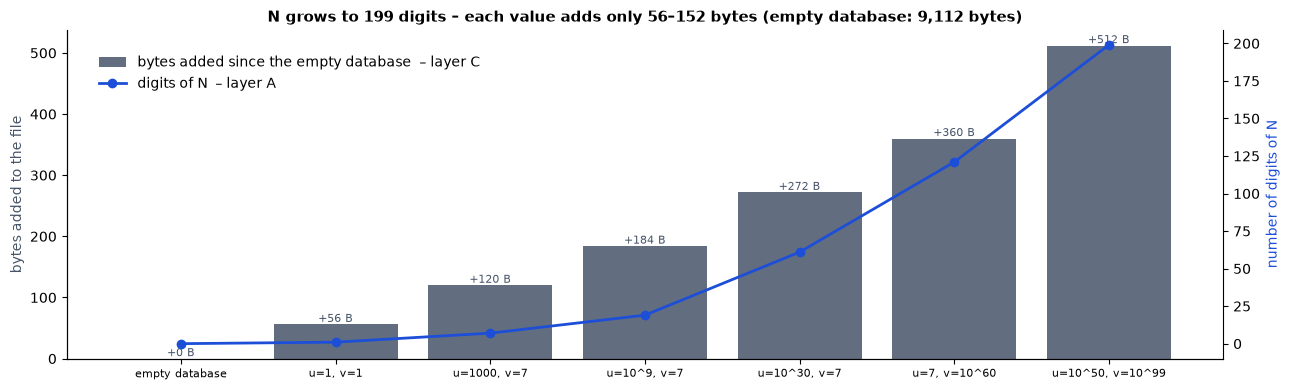

fixed part: two superblocks of 8192 bytes; the rest are small blocks.


In [10]:
fig, ax1 = plt.subplots(figsize=(13, 4))
x = range(len(growth))
ax1.bar(x, growth["bytes for values"], color=COLORS["C"], alpha=0.85,
        label="bytes added since the empty database  – layer C")
for xi, b in zip(x, growth["bytes for values"]):
    ax1.text(xi, b + 4, f"+{b} B", ha="center", fontsize=8, color=COLORS["C"])
ax1.set_ylabel("bytes added to the file", color=COLORS["C"])
ax1.set_xticks(list(x))
ax1.set_xticklabels(growth["step"], fontsize=8)
ax2 = ax1.twinx()
ax2.plot(list(x), growth["N digits"], "o-", color=COLORS["A"], lw=2, label="digits of N  – layer A")
ax2.set_ylabel("number of digits of N", color=COLORS["A"])
ax2.spines["right"].set_visible(True)
added = growth["added bytes"][1:]
ax1.set_title(f"N grows to {growth['N digits'].max()} digits – each value adds only {added.min()}–{added.max()} bytes "
              f"(empty database: {growth['file bytes'][0]:,} bytes)")
fig.legend(loc="upper left", bbox_to_anchor=(0.07, 0.88), frameon=False)
plt.tight_layout()
plt.show()

with nhydb.open(FAR) as db:
    storage = db.stats()["storage"]
print("fixed part: two superblocks of", storage["superblocks_bytes"], "bytes; the rest are small blocks.")

**What happened?** The number `N` of the last value has about 200 digits, yet each value added
well under 200 bytes – a small block with the value and its coordinates. Very large coordinates
cost a few extra bytes because the coordinates themselves are written compactly
(variable-length integers); the empty space *between* the addresses costs nothing. Most of the
file is the fixed part at its start (two superblocks of 8 KiB together).
**Ah – addresses are free; only values cost space.**

## 6 · ▶ Your own data

**Change it:** replace the rows with your own list (three fields: text, text, number) and run
the cell. It builds a fresh database and shows where your records live.

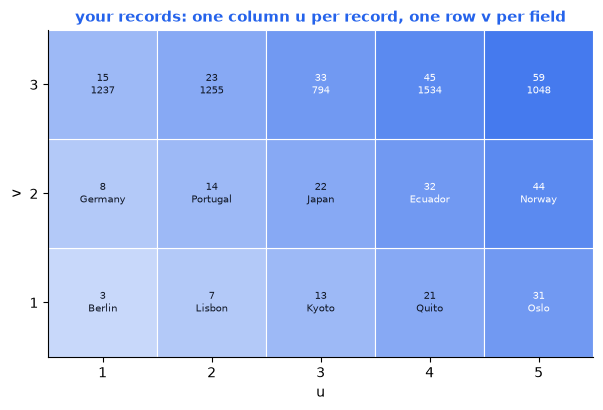

In [11]:
# ▶ Try it: change these values and re-run
MY_ROWS = [
    ["Berlin", "Germany", 1237],
    ["Lisbon", "Portugal", 1255],
    ["Kyoto", "Japan", 794],
    ["Quito", "Ecuador", 1534],
    ["Oslo", "Norway", 1048],
]
FIELDS = [("name", "utf8"), ("country", "utf8"), ("founded", "u16")]

MINE = db_path("mine.nhydb")
with nhydb.create(MINE, overwrite=True) as db:
    db.create_realm(1, "mine")
    db.create_shape(1, 1, "row", [{"v": i + 1, "name": n, "type": t} for i, (n, t) in enumerate(FIELDS)])
    db.create_classic_layout(1, 1, "rows", shape_id=1)
    db.put_dense_batch(1, 1, MY_ROWS, shape_id=1)

with nhydb.open(MINE) as db:
    shown = {(u, v): str(db.get_value(1, u, v))[:9] for u in range(1, len(MY_ROWS) + 1)
             for v in range(1, len(FIELDS) + 1)}
fig, ax = plt.subplots(figsize=(min(13, 2 + 1.6 * len(MY_ROWS)), 4.2))
plot_address_grid(ax, len(MY_ROWS), len(FIELDS), "NL", values=shown,
                  title="your records: one column u per record, one row v per field")
plt.tight_layout()
plt.show()

## 7 · Your turn

**Task:** read the `year` of *Proofs from THE BOOK* using **only its number `N`**. First work out
the cell (which `u`, which `v`?), then the number, then read.

In [12]:
# Solution: book 4 → u = 4; year is field 3 → v = 3; lane NL.  G = 7, N = 49 − 4 = 45.
n_year = nhydb.dynadron_n(1, 4, 3, "NL")
with nhydb.open(PATH) as db:
    answer = db.get_n(n_year, mode="cell")
print(f"N = {n_year} → {answer['field']} = {answer['value']}")
assert n_year == 45 and answer["value"] == 1998

N = 45 → year = 1998


## ⏩ Advanced: the same from the command line

The package installs a command `nhydb` (also `python -m nhydb`). It converts addresses and
numbers and reads cells – handy for quick checks without writing Python.

In [13]:
import json
import subprocess


def cli(*args):
    out = subprocess.run([sys.executable, "-m", "nhydb", *args, "--json"],
                         capture_output=True, text=True, check=True).stdout
    return json.loads(out)


print("to-n  :", cli("to-n", "--realm", "1", "--u", "3", "--v", "2", "--lane", "NL")["N"])
print("from-n:", {k: cli("from-n", "N45")[k] for k in ("realm", "u", "v_local", "lane_name")})
print("get   :", cli("get", PATH, "u4,v3", "--realm", "1", "--mode", "cell")["value"])

to-n  : 22


from-n: {'realm': 1, 'u': 4, 'v_local': 3, 'lane_name': 'NL'}
get   : 1998


## Summary

* A realm, a shape and a CLASSIC layout are all it takes: record = `u`, field = `v`.
* Every stored value has a cell and a number `N`; fields of one record lie in different groups – and that is fine.
* Coordinates, record and number are three ways to the same value; anchors (`v = 1`) give whole records.
* Data survives closing and reopening; distant addresses cost no space – only values do.

## Where to go next

* [03 · Records, Fields and Lanes](03_records_fields_and_lanes_v1.ipynb) – the full data model.
* [05 · MATH_MAP](05_math_map_text_and_formula_lab_v1.ipynb) – let a formula choose where data goes.
* [11 · What Actually Lives on Disk?](11_what_lives_on_disk_v1.ipynb) – the files in detail.

**Cookbook sections:** 3 (Your first database), 6 (Records), 10 (Reading by N), 24 (Command line) in the [NHyDB Python Cookbook](https://github.com/nhydb-run4/NHyDB/blob/main/docs/cookbook/PYTHON_COOKBOOK.md).

In [14]:
# Clean up: remove the temporary folder with all databases of this notebook.
cleanup()
print("Temporary files removed.")

Temporary files removed.
